# Thesis Visualizations Notebook (robust to your CSV schema)

Put this file into your project root, e.g. **`D:\progr`**, then open and **Run All**.

It will:
- read `outputs/results/metrics.csv` and (if present) `outputs/results/dm_tests.csv`
- create figures in `outputs/figures_notebook/`
- export LaTeX-friendly tables into `outputs/tables_notebook/`
- optionally run a **GPU LSTM baseline** (RTX 4060) if CUDA PyTorch is available and prediction files exist

> Your `metrics.csv` currently uses column `window` (not `w`). This notebook auto-detects and maps columns.


In [1]:
import os
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use Jupyter's display (do NOT import networkx.display)
from IPython.display import display

try:
    import torch
    import torch.nn as nn
except Exception as e:
    torch = None
    nn = None
    print("PyTorch not available:", e)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 240


In [2]:
# ---- Paths (assumes notebook is located in project root) ----
ROOT = Path(".").resolve()
OUTPUTS = ROOT / "outputs"
RESULTS = OUTPUTS / "results"
PREDICTIONS = OUTPUTS / "predictions"
NBFIG = OUTPUTS / "figures_notebook"
NBTEX = OUTPUTS / "tables_notebook"

NBFIG.mkdir(parents=True, exist_ok=True)
NBTEX.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RESULTS:", RESULTS, "exists=", RESULTS.exists())
print("PREDICTIONS:", PREDICTIONS, "exists=", PREDICTIONS.exists())
print("NBFIG:", NBFIG)
print("NBTEX:", NBTEX)


ROOT: D:\progr
RESULTS: D:\progr\outputs\results exists= True
PREDICTIONS: D:\progr\outputs\predictions exists= True
NBFIG: D:\progr\outputs\figures_notebook
NBTEX: D:\progr\outputs\tables_notebook


In [3]:
# ---- GPU check ----
if torch is None:
    device = "cpu"
    print("Device: CPU (PyTorch not installed)")
else:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device:", device)
    if device == "cuda":
        print("CUDA device:", torch.cuda.get_device_name(0))
        print("Compute capability:", torch.cuda.get_device_capability(0))
        print("CUDA version (torch):", torch.version.cuda)
    else:
        print("CUDA not available. If you expected RTX 4060, install CUDA-enabled PyTorch for Python 3.11.")


Device: cpu
CUDA not available. If you expected RTX 4060, install CUDA-enabled PyTorch for Python 3.11.


In [4]:
# ---- Load metrics + DM tests ----
metrics_path = RESULTS / "metrics.csv"
dm_path = RESULTS / "dm_tests.csv"

assert metrics_path.exists(), f"Missing {metrics_path}. Run your pipeline first."
metrics_raw = pd.read_csv(metrics_path)

print("metrics.csv columns:", list(metrics_raw.columns))
print("metrics shape:", metrics_raw.shape)
display(metrics_raw.head(10))

dm_raw = None
if dm_path.exists():
    dm_raw = pd.read_csv(dm_path)
    print("dm_tests.csv columns:", list(dm_raw.columns))
    print("dm_tests shape:", dm_raw.shape)
    display(dm_raw.head(10))
else:
    print("dm_tests.csv not found (OK).")


metrics.csv columns: ['dependency', 'window', 'target_space', 'model', 'MAE', 'RMSE', 'R2', 'n_test']
metrics shape: (120, 8)


,dependency,window,target_space,model,MAE,RMSE,R2,n_test
0,corr_BTC-USD_^GSPC,14,fisher_z,AR1,0.088039,0.126297,0.868947,1255
1,corr_BTC-USD_^GSPC,14,fisher_z,Naive_Last,0.087919,0.127862,0.865678,1255
2,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,0.132550,0.175257,0.747644,1255
3,corr_BTC-USD_^GSPC,14,fisher_z,RF,0.144552,0.186337,0.714725,1255
4,corr_BTC-USD_^GSPC,14,fisher_z,ElasticNet,0.320505,0.396812,-0.293702,1255
5,corr_BTC-USD_^GSPC,30,fisher_z,AR1,0.037334,0.058634,0.950826,1239
6,corr_BTC-USD_^GSPC,30,fisher_z,Naive_Last,0.036935,0.058815,0.950522,1239
7,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,0.057792,0.083880,0.899365,1239
8,corr_BTC-USD_^GSPC,30,fisher_z,RF,0.067173,0.093549,0.874826,1239
9,corr_BTC-USD_^GSPC,30,fisher_z,ElasticNet,0.269685,0.323107,-0.493237,1239


dm_tests.csv columns: ['dependency', 'window', 'space', 'model', 'benchmark', 'DM_stat', 'p_value', 'n']
dm_tests shape: (48, 8)


,dependency,window,space,model,benchmark,DM_stat,p_value,n
0,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,Naive_Last,-11.880939,0.000000e+00,1255.0
1,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,DCC_GARCH,16.354195,0.000000e+00,1255.0
2,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,Naive_Last,-9.833022,0.000000e+00,1239.0
3,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,DCC_GARCH,18.051013,0.000000e+00,1239.0
4,corr_BTC-USD_^GSPC,60,fisher_z,Ridge,Naive_Last,-8.205213,6.661338e-16,1209.0
5,corr_BTC-USD_^GSPC,60,fisher_z,Ridge,DCC_GARCH,22.059640,0.000000e+00,1209.0
6,corr_BTC-USD_^GSPC,90,fisher_z,Ridge,Naive_Last,-7.045262,3.141931e-12,1179.0
7,corr_BTC-USD_^GSPC,90,fisher_z,Ridge,DCC_GARCH,27.272930,0.000000e+00,1179.0
8,corr_BTC-USD_^IXIC,14,fisher_z,Ridge,Naive_Last,-11.722002,0.000000e+00,1255.0
9,corr_BTC-USD_^IXIC,14,fisher_z,Ridge,DCC_GARCH,15.910565,0.000000e+00,1255.0


In [5]:
# ---- Normalize column names (schema mapping) ----
# Your schema example:
# ['dependency','window','target_space','model','MAE','RMSE','R2','n_test']
#
# We normalize to:
# dependency, w, target_space, model, MAE, RMSE, R2, n

metrics = metrics_raw.copy()

rename_map = {}
if "w" not in metrics.columns and "window" in metrics.columns:
    rename_map["window"] = "w"
if "target_space" not in metrics.columns and "space" in metrics.columns:
    rename_map["space"] = "target_space"
if "n" not in metrics.columns and "n_test" in metrics.columns:
    rename_map["n_test"] = "n"
if "R2" not in metrics.columns and "R^2" in metrics.columns:
    rename_map["R^2"] = "R2"

metrics = metrics.rename(columns=rename_map)

# Ensure required columns exist
required = {"dependency","w","model","RMSE"}
missing = required - set(metrics.columns)
assert not missing, f"Still missing {missing}. Columns={list(metrics.columns)}"

# Type fixes
metrics["w"] = metrics["w"].astype(int)
metrics["RMSE"] = metrics["RMSE"].astype(float)
if "MAE" in metrics.columns: metrics["MAE"] = metrics["MAE"].astype(float)
if "R2" in metrics.columns: metrics["R2"] = metrics["R2"].astype(float)

print("Normalized columns:", list(metrics.columns))
display(metrics.head(5))


Normalized columns: ['dependency', 'w', 'target_space', 'model', 'MAE', 'RMSE', 'R2', 'n']


,dependency,w,target_space,model,MAE,RMSE,R2,n
0,corr_BTC-USD_^GSPC,14,fisher_z,AR1,0.088039,0.126297,0.868947,1255
1,corr_BTC-USD_^GSPC,14,fisher_z,Naive_Last,0.087919,0.127862,0.865678,1255
2,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,0.132550,0.175257,0.747644,1255
3,corr_BTC-USD_^GSPC,14,fisher_z,RF,0.144552,0.186337,0.714725,1255
4,corr_BTC-USD_^GSPC,14,fisher_z,ElasticNet,0.320505,0.396812,-0.293702,1255


In [6]:
# ---- Best model per (dependency, window) by RMSE ----
best = (metrics.sort_values(["dependency","w","RMSE"])
        .groupby(["dependency","w"], as_index=False)
        .first())

print("Unique dependencies:", best["dependency"].nunique())
print("Windows:", sorted(best["w"].unique()))
display(best.head(20))


Unique dependencies: 6
Windows: [np.int64(14), np.int64(30), np.int64(60), np.int64(90)]


,dependency,w,target_space,model,MAE,RMSE,R2,n
0,corr_BTC-USD_ETH-USD,14,fisher_z,AR1,0.101089,0.156772,0.875030,1255
1,corr_BTC-USD_ETH-USD,30,fisher_z,AR1,0.043828,0.071976,0.956765,1239
2,corr_BTC-USD_ETH-USD,60,fisher_z,AR1,0.020726,0.037388,0.980280,1209
3,corr_BTC-USD_ETH-USD,90,fisher_z,AR1,0.012824,0.023703,0.987883,1179
4,corr_BTC-USD_GLD,14,fisher_z,AR1,0.088535,0.135544,0.838662,1255
5,corr_BTC-USD_GLD,30,fisher_z,AR1,0.037582,0.062366,0.927341,1239
6,corr_BTC-USD_GLD,60,fisher_z,AR1,0.018335,0.033244,0.963336,1209
7,corr_BTC-USD_GLD,90,fisher_z,AR1,0.011824,0.021250,0.979735,1179
8,corr_BTC-USD_SLV,14,fisher_z,AR1,0.083070,0.123112,0.860062,1255
9,corr_BTC-USD_SLV,30,fisher_z,AR1,0.036637,0.058208,0.941800,1239


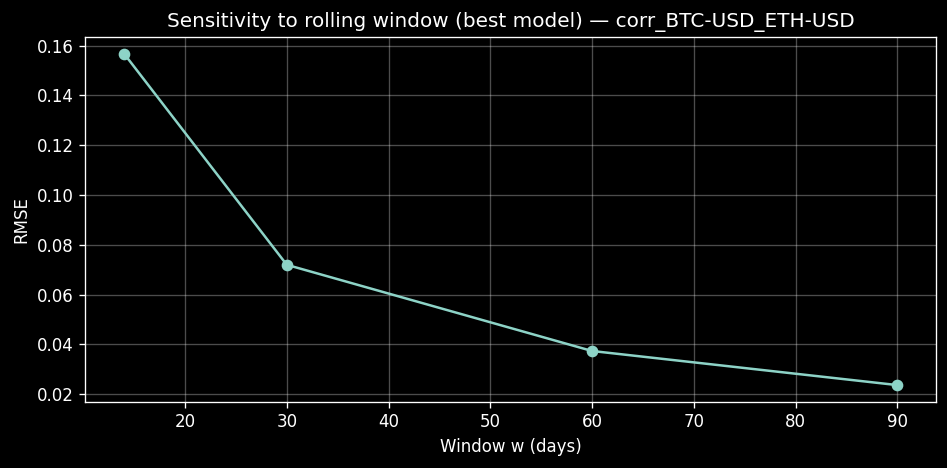

Saved: D:\progr\outputs\figures_notebook\sensitivity_corr_BTC-USD_ETH-USD.png


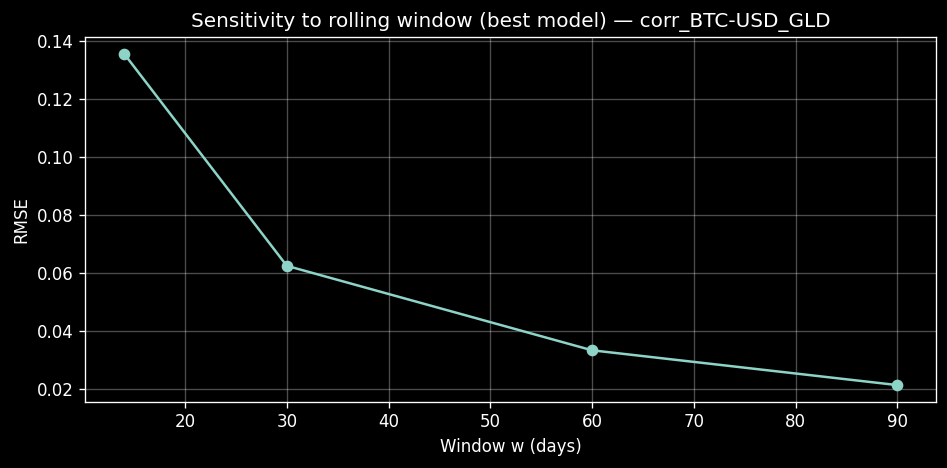

Saved: D:\progr\outputs\figures_notebook\sensitivity_corr_BTC-USD_GLD.png


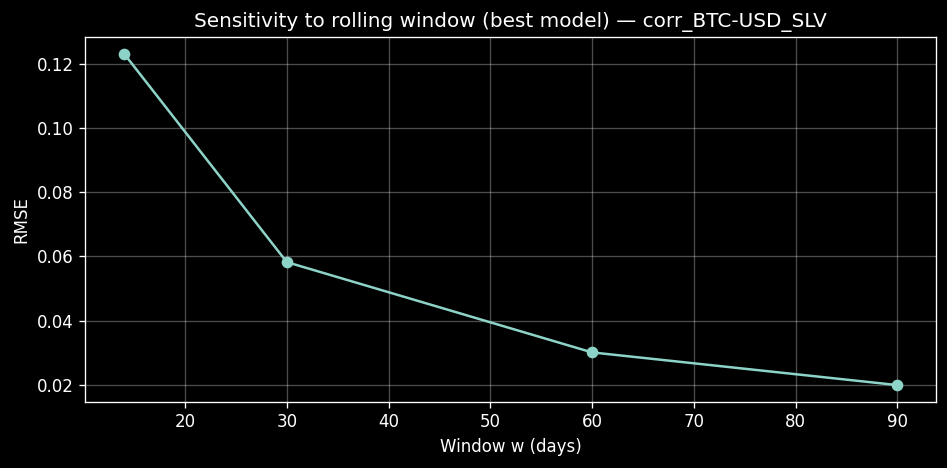

Saved: D:\progr\outputs\figures_notebook\sensitivity_corr_BTC-USD_SLV.png


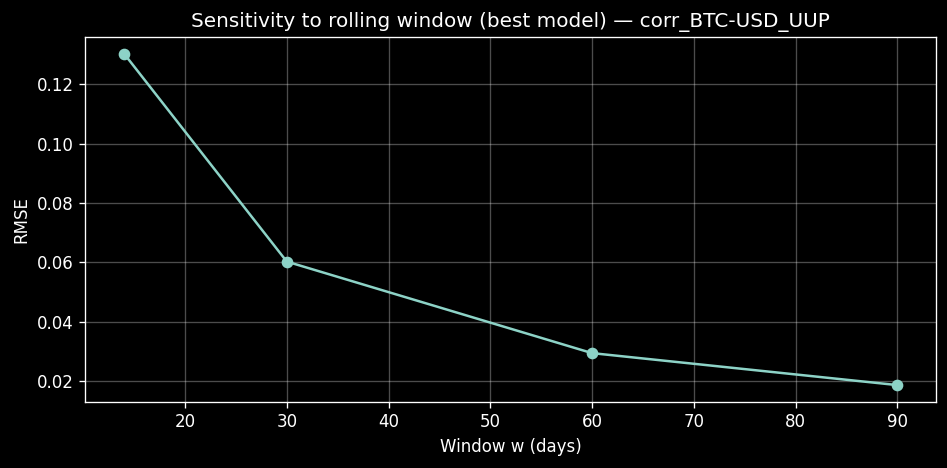

Saved: D:\progr\outputs\figures_notebook\sensitivity_corr_BTC-USD_UUP.png


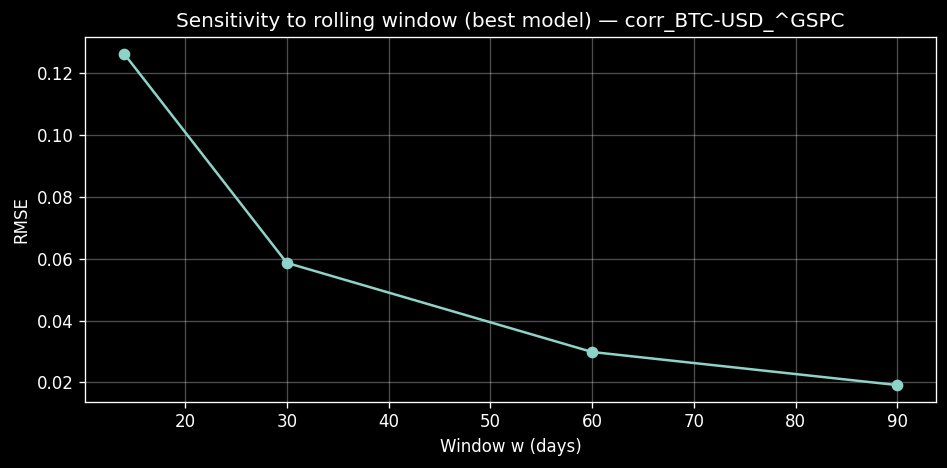

Saved: D:\progr\outputs\figures_notebook\sensitivity_corr_BTC-USD_^GSPC.png


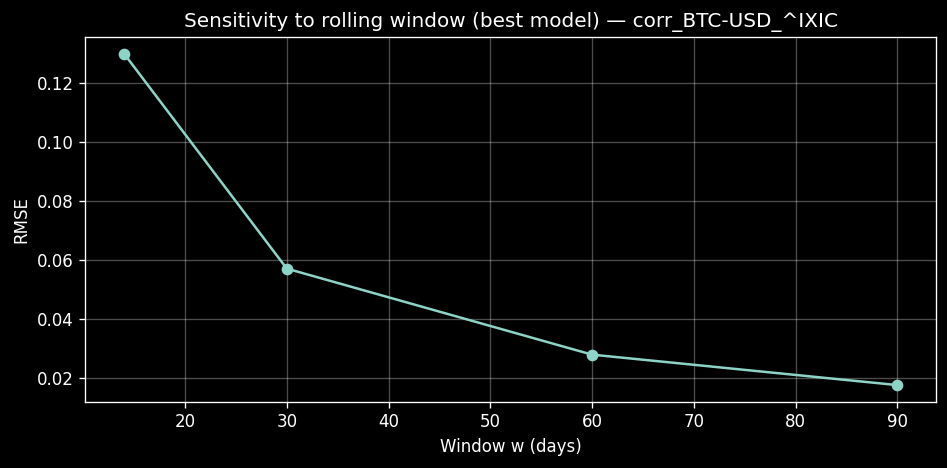

Saved: D:\progr\outputs\figures_notebook\sensitivity_corr_BTC-USD_^IXIC.png


In [7]:
# ---- Plot 1: Window sensitivity (RMSE vs w) for each dependency ----
for dep in sorted(best["dependency"].unique()):
    d = best[best["dependency"] == dep].sort_values("w")
    plt.figure(figsize=(8,4))
    plt.plot(d["w"], d["RMSE"], marker="o")
    plt.title(f"Sensitivity to rolling window (best model) — {dep}")
    plt.xlabel("Window w (days)")
    plt.ylabel("RMSE")
    plt.grid(True, alpha=0.3)
    out = NBFIG / f"sensitivity_{dep}.png"
    plt.tight_layout()
    plt.savefig(out)
    plt.show()
    print("Saved:", out)


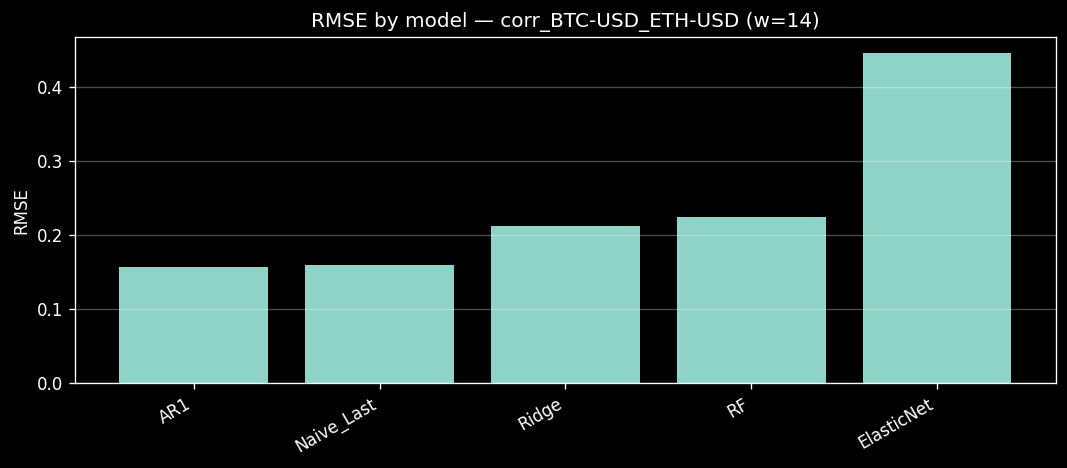

Saved: D:\progr\outputs\figures_notebook\rmse_by_model_corr_BTC-USD_ETH-USD_w14.png


In [8]:
# ---- Plot 2: RMSE by model for a selected dependency + window ----
def plot_rmse_by_model(dep: str, w: int):
    d = metrics[(metrics["dependency"]==dep) & (metrics["w"]==w)].copy().sort_values("RMSE")
    plt.figure(figsize=(9,4))
    plt.bar(d["model"].astype(str), d["RMSE"].astype(float))
    plt.title(f"RMSE by model — {dep} (w={w})")
    plt.ylabel("RMSE")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    out = NBFIG / f"rmse_by_model_{dep}_w{w}.png"
    plt.tight_layout()
    plt.savefig(out)
    plt.show()
    print("Saved:", out)

dep0 = sorted(metrics["dependency"].unique())[0]
w0 = int(sorted(metrics["w"].unique())[0])
plot_rmse_by_model(dep0, w0)


In [9]:
# ---- Export LaTeX tables (robust, no underscores issues) ----
# 1) Best models by window
best_tex = best.copy()
best_tex_path = NBTEX / "best_models_by_window.tex"
best_tex.to_latex(best_tex_path, index=False, float_format="%.4f", escape=True)
print("Saved:", best_tex_path)

# 2) Full metrics (optional, can be large)
full_tex_path = NBTEX / "metrics_full.tex"
metrics.to_latex(full_tex_path, index=False, float_format="%.4f", escape=True)
print("Saved:", full_tex_path)


Saved: D:\progr\outputs\tables_notebook\best_models_by_window.tex
Saved: D:\progr\outputs\tables_notebook\metrics_full.tex


In [10]:
# ---- DM-test visualization (if dm_tests.csv exists) ----
# We try to detect common column patterns.
if dm_raw is None:
    print("No DM test file -> skipping.")
else:
    dm = dm_raw.copy()
    # Normalize columns if needed
    # expected: dependency, window/w, model_a, model_b, p_value
    if "w" not in dm.columns and "window" in dm.columns:
        dm = dm.rename(columns={"window":"w"})
    if "p_value" not in dm.columns:
        # common alternatives
        for alt in ["p", "pval", "pvalue", "p-val", "p_val"]:
            if alt in dm.columns:
                dm = dm.rename(columns={alt:"p_value"})
                break

    needed = {"dependency","w","model_a","model_b","p_value"}
    if not needed.issubset(dm.columns):
        print("DM tests columns not recognized. Columns:", list(dm.columns))
    else:
        dm["w"] = dm["w"].astype(int)
        dm["p_value"] = dm["p_value"].astype(float)

        alpha = 0.05
        dep0 = sorted(dm["dependency"].unique())[0]
        w0 = int(sorted(dm["w"].unique())[0])

        sub = dm[(dm["dependency"]==dep0) & (dm["w"]==w0)].copy()
        models = sorted(set(sub["model_a"]).union(set(sub["model_b"])))
        mat = pd.DataFrame(0, index=models, columns=models, dtype=int)
        for _, r in sub.iterrows():
            if float(r["p_value"]) < alpha:
                mat.loc[r["model_a"], r["model_b"]] = 1

        plt.figure(figsize=(7,6))
        plt.imshow(mat.values)
        plt.xticks(range(len(models)), models, rotation=45, ha="right")
        plt.yticks(range(len(models)), models)
        plt.title(f"DM-test significance matrix (p<{alpha}) — {dep0} (w={w0})")
        plt.colorbar()
        out = NBFIG / f"dm_matrix_{dep0}_w{w0}.png"
        plt.tight_layout()
        plt.savefig(out)
        plt.show()
        print("Saved:", out)

        # Export DM tests as LaTeX too
        dm_tex_path = NBTEX / "dm_tests.tex"
        dm.to_latex(dm_tex_path, index=False, float_format="%.4g", escape=True)
        print("Saved:", dm_tex_path)


DM tests columns not recognized. Columns: ['dependency', 'w', 'space', 'model', 'benchmark', 'DM_stat', 'p_value', 'n']


## Optional: Sequence model baseline (LSTM) on GPU

Your supervisor mentioned **RNN/Transformers** for sequences. This cell runs a minimal **LSTM regression baseline**.

It requires at least one file in `outputs/predictions/*.csv` containing a target column (e.g., `y_true`, `actual`, or any numeric series).  
If you don't have prediction exports, this section will skip safely.


In [11]:
pred_files = list(PREDICTIONS.glob("*.csv")) if PREDICTIONS.exists() else []
print("prediction files found:", len(pred_files))
if len(pred_files) == 0:
    print("No prediction files in outputs/predictions -> skipping LSTM section.")
else:
    p = pred_files[0]
    dfp = pd.read_csv(p)
    print("Using:", p.name)
    print("Columns:", list(dfp.columns))
    display(dfp.head())


prediction files found: 30
Using: corr_BTC-USD_ETH-USD_predictions.csv
Columns: ['Date', 'y_true', 'Naive_Last', 'AR1', 'Ridge', 'RF', 'XGB_GPU']


,Date,y_true,Naive_Last,AR1,Ridge,RF,XGB_GPU
0,2018-01-03,0.193127,NaN,NaN,NaN,NaN,NaN
1,2018-01-04,0.175224,NaN,NaN,NaN,NaN,NaN
2,2018-01-05,0.088645,NaN,NaN,NaN,NaN,NaN
3,2018-01-08,0.086599,NaN,NaN,NaN,NaN,NaN
4,2018-01-09,0.103734,NaN,NaN,NaN,NaN,NaN


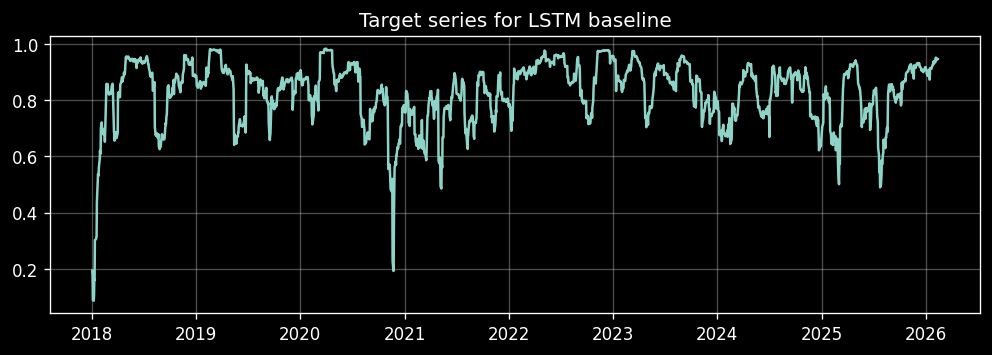

Epoch 01/15 | train MSE 0.7080 | test MSE 0.6896
Epoch 02/15 | train MSE 0.6187 | test MSE 0.5316
Epoch 03/15 | train MSE 0.4056 | test MSE 0.2978
Epoch 04/15 | train MSE 0.3002 | test MSE 0.2462
Epoch 05/15 | train MSE 0.2252 | test MSE 0.2355
Epoch 06/15 | train MSE 0.1995 | test MSE 0.1818
Epoch 07/15 | train MSE 0.1570 | test MSE 0.1636
Epoch 08/15 | train MSE 0.1391 | test MSE 0.1339
Epoch 09/15 | train MSE 0.1150 | test MSE 0.1169
Epoch 10/15 | train MSE 0.1060 | test MSE 0.1057
Epoch 11/15 | train MSE 0.1024 | test MSE 0.0951
Epoch 12/15 | train MSE 0.0992 | test MSE 0.0890
Epoch 13/15 | train MSE 0.0873 | test MSE 0.0809
Epoch 14/15 | train MSE 0.0870 | test MSE 0.0763
Epoch 15/15 | train MSE 0.0764 | test MSE 0.0711
LSTM baseline | MAE: 0.02081130156826199 | RMSE: 0.030952088296434702


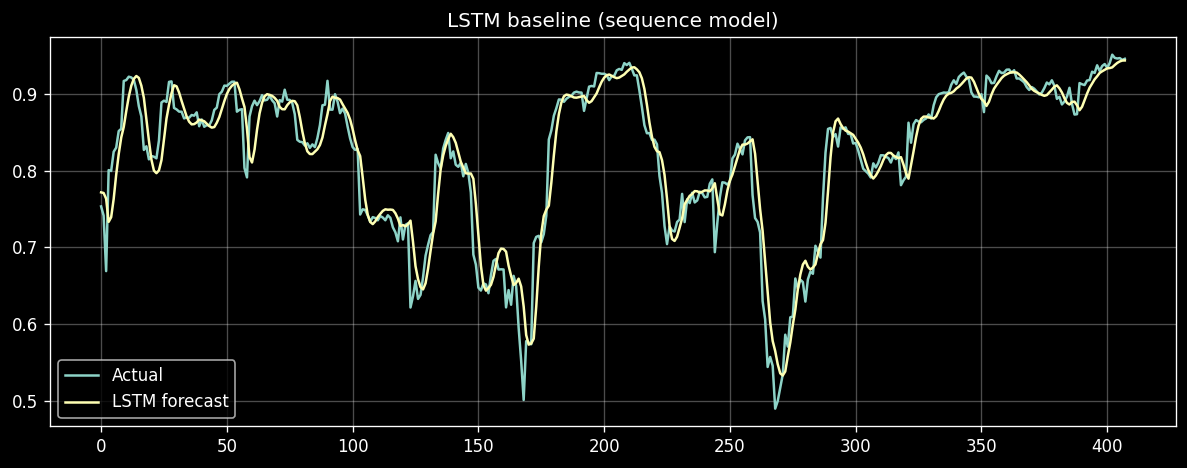

Saved: D:\progr\outputs\figures_notebook\lstm_baseline_forecast.png


In [12]:
if torch is None or len(pred_files) == 0:
    print("Skipping LSTM (PyTorch missing or no series).")
else:
    cols_map = {c.lower(): c for c in dfp.columns}
    date_col = cols_map.get("date", dfp.columns[0])
    true_col = cols_map.get("y_true", cols_map.get("actual", cols_map.get("target", None)))

    if true_col is None:
        num_cols = [c for c in dfp.columns if pd.api.types.is_numeric_dtype(dfp[c])]
        true_col = num_cols[0] if num_cols else None
    assert true_col is not None, f"Cannot detect target column in {p.name}"

    s = dfp[[date_col, true_col]].copy()
    s[date_col] = pd.to_datetime(s[date_col], errors="coerce")
    s = s.dropna(subset=[date_col]).sort_values(date_col)
    y = s[true_col].astype(float).values

    plt.figure(figsize=(10,3))
    plt.plot(s[date_col], y)
    plt.title("Target series for LSTM baseline")
    plt.grid(True, alpha=0.3)
    plt.show()

    lookback = 60
    horizon = 1
    hidden = 64
    layers = 2
    epochs = 15
    batch_size = 256
    lr = 1e-3

    split = int(len(y) * 0.8)
    y_train = y[:split]
    y_test = y[split-lookback:]

    mu, sigma = y_train.mean(), y_train.std() + 1e-8
    y_train_n = (y_train - mu) / sigma
    y_test_n = (y_test - mu) / sigma

    def make_xy(arr, lookback, horizon):
        X, Y = [], []
        for i in range(lookback, len(arr) - horizon + 1):
            X.append(arr[i-lookback:i])
            Y.append(arr[i + horizon - 1])
        X = np.array(X, dtype=np.float32)[:, :, None]
        Y = np.array(Y, dtype=np.float32)[:, None]
        return X, Y

    Xtr, Ytr = make_xy(y_train_n, lookback, horizon)
    Xte, Yte = make_xy(y_test_n, lookback, horizon)

    class LSTMReg(nn.Module):
        def __init__(self, hidden=64, layers=2):
            super().__init__()
            self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, num_layers=layers, batch_first=True)
            self.fc = nn.Linear(hidden, 1)
        def forward(self, x):
            out, _ = self.lstm(x)
            return self.fc(out[:, -1, :])

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = LSTMReg(hidden=hidden, layers=layers).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    Xtr_t = torch.from_numpy(Xtr).to(device)
    Ytr_t = torch.from_numpy(Ytr).to(device)
    Xte_t = torch.from_numpy(Xte).to(device)
    Yte_t = torch.from_numpy(Yte).to(device)

    n_batches = math.ceil(len(Xtr) / batch_size)

    model.train()
    for ep in range(1, epochs+1):
        perm = torch.randperm(len(Xtr_t), device=device)
        ep_loss = 0.0
        for bi in range(n_batches):
            idx = perm[bi*batch_size:(bi+1)*batch_size]
            xb = Xtr_t[idx]
            yb = Ytr_t[idx]
            opt.zero_grad(set_to_none=True)
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            opt.step()
            ep_loss += loss.item()
        ep_loss /= max(1, n_batches)

        model.eval()
        with torch.no_grad():
            te_pred = model(Xte_t)
            te_mse = loss_fn(te_pred, Yte_t).item()
        model.train()
        print(f"Epoch {ep:02d}/{epochs} | train MSE {ep_loss:.4f} | test MSE {te_mse:.4f}")

    model.eval()
    with torch.no_grad():
        te_pred = model(Xte_t).detach().cpu().numpy().flatten()
        te_true = Yte_t.detach().cpu().numpy().flatten()

    te_pred_dn = te_pred * sigma + mu
    te_true_dn = te_true * sigma + mu

    rmse = float(np.sqrt(np.mean((te_pred_dn - te_true_dn)**2)))
    mae = float(np.mean(np.abs(te_pred_dn - te_true_dn)))
    print("LSTM baseline | MAE:", mae, "| RMSE:", rmse)

    plt.figure(figsize=(10,4))
    plt.plot(te_true_dn, label="Actual")
    plt.plot(te_pred_dn, label="LSTM forecast")
    plt.title("LSTM baseline (sequence model)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    out = NBFIG / "lstm_baseline_forecast.png"
    plt.tight_layout()
    plt.savefig(out)
    plt.show()
    print("Saved:", out)


In [14]:
#0) Проверка: XGBoost видит GPU
import xgboost as xgb
import numpy as np

print("xgboost version:", xgb.__version__)

# Быстрый smoke-test: пробуем обучить на GPU
X = np.random.randn(5000, 20)
y = X[:, 0] * 0.5 + np.random.randn(5000) * 0.1

model = xgb.XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    device="cuda",   # <-- ключ
    random_state=42
)

model.fit(X, y)
print("OK: trained with device=cuda")

xgboost version: 3.2.0
OK: trained with device=cuda


In [15]:
#1) Загрузка одного prediction-файла и подготовка датасета под XGBoost
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(".").resolve()
OUT = ROOT / "outputs"
PRED_DIR = OUT / "predictions"
FIG_DIR = OUT / "figures_notebook"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Выбери любой файл (лучше w30 fisher_z)
pred_file = next(PRED_DIR.glob("*w30*fisher_z*predictions.csv"))
print("Using:", pred_file.name)

df = pd.read_csv(pred_file)

# Посмотри колонки
print(df.columns.tolist())
df.head()

Using: corr_BTC-USD_ETH-USD_w30_fisher_z_predictions.csv
['Date', 'y_true', 'Naive_Last', 'AR1', 'ElasticNet', 'Ridge', 'RF', 'XGB_GPU', 'DCC_GARCH']


,Date,y_true,Naive_Last,AR1,ElasticNet,Ridge,RF,XGB_GPU,DCC_GARCH
0,2018-01-03,0.195584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-01-04,0.177051,NaN,NaN,NaN,NaN,NaN,NaN,1.144201
2,2018-01-05,0.088878,NaN,NaN,NaN,NaN,NaN,NaN,1.146051
3,2018-01-08,0.086816,NaN,NaN,NaN,NaN,NaN,NaN,1.035681
4,2018-01-09,0.104108,NaN,NaN,NaN,NaN,NaN,NaN,0.545665


In [16]:
#2) Генерация лаговых признаков (то, что реально делает задачу ML)
def make_lag_features(series: pd.Series, lags: int = 30):
    X = {}
    for k in range(1, lags+1):
        X[f"lag_{k}"] = series.shift(k)
    return pd.DataFrame(X)

# target: фактическая серия
# если у тебя таргет называется иначе — поменяй тут
y = df["y_true"].astype(float)

# лаги
lags = 30
X = make_lag_features(y, lags=lags)

data = pd.concat([df, X], axis=1).dropna().reset_index(drop=True)
X = data[[c for c in data.columns if c.startswith("lag_")]]
y = data["y_true"].astype(float)

print("X shape:", X.shape, "y shape:", y.shape)

X shape: (0, 30) y shape: (0,)


Using file: corr_BTC-USD_ETH-USD_w14_fisher_z_predictions.csv
Rows: 2055
Columns: ['Date', 'y_true', 'Naive_Last', 'AR1', 'ElasticNet', 'Ridge', 'RF', 'XGB_GPU', 'DCC_GARCH']
Target column: y_true
Using lags: 30
Final dataset size: 2025
Train: 1620 Test: 405


D:\progr\.venv\Lib\site-packages\xgboost\core.py:751: UserWarning: [21:11:44] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



XGBoost GPU results
MAE: 0.10451883563023709
RMSE: 0.14749133852957613
R2: 0.8656494559905266


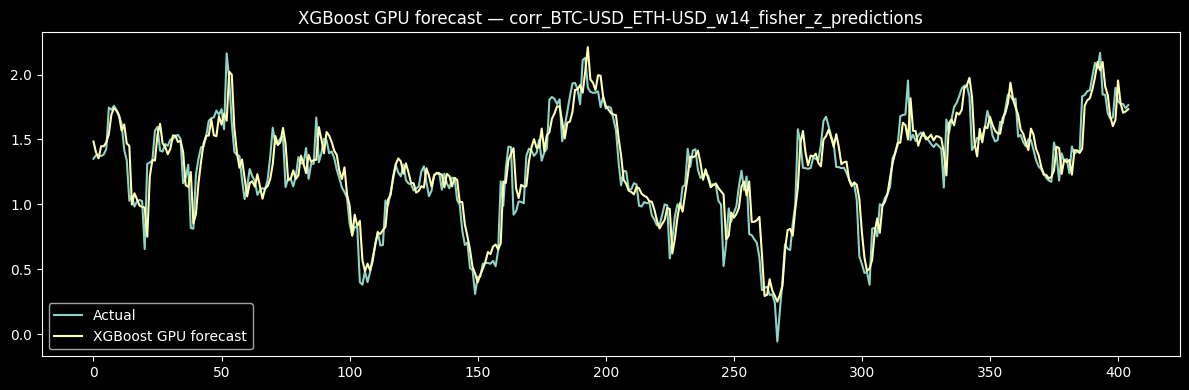

Saved: D:\progr\outputs\figures_notebook\xgb_gpu_forecast_corr_BTC-USD_ETH-USD_w14_fisher_z_predictions.png


In [2]:
#3) Честный time split + XGBoost GPU
from pathlib import Path
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
PRED_DIR = ROOT / "outputs" / "predictions"
FIG_DIR = ROOT / "outputs" / "figures_notebook"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- 1. Найти самый длинный predictions-файл ---
files = list(PRED_DIR.glob("*.csv"))
assert len(files) > 0, "No prediction files found"

file_lengths = []
for f in files:
    try:
        n = len(pd.read_csv(f))
        file_lengths.append((f, n))
    except:
        pass

file_lengths.sort(key=lambda x: x[1], reverse=True)
pred_file = file_lengths[0][0]

print("Using file:", pred_file.name)

df = pd.read_csv(pred_file)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

# --- 2. Найти колонку таргета ---
lower_cols = {c.lower(): c for c in df.columns}

if "y_true" in lower_cols:
    target_col = lower_cols["y_true"]
elif "actual" in lower_cols:
    target_col = lower_cols["actual"]
else:
    # взять первую числовую
    num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    target_col = num_cols[0]

print("Target column:", target_col)

series = df[target_col].astype(float)

# --- 3. Лаги ---
max_lags = 30
lags = min(max_lags, len(series)//10)  # авто-подбор
print("Using lags:", lags)

X_dict = {}
for k in range(1, lags+1):
    X_dict[f"lag_{k}"] = series.shift(k)

X = pd.DataFrame(X_dict)
data = pd.concat([series, X], axis=1).dropna().reset_index(drop=True)

y = data[target_col]
X = data.drop(columns=[target_col])

print("Final dataset size:", len(data))

assert len(data) > 100, "Too few rows after lagging. Choose another file."

# --- 4. Split ---
test_size = max(100, int(len(data)*0.2))
split = len(data) - test_size

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", len(X_train), "Test:", len(X_test))

# --- 5. XGBoost GPU ---
model = xgb.XGBRegressor(
    n_estimators=1500,
    learning_rate=0.02,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    device="cuda",
    random_state=42
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

mae = float(mean_absolute_error(y_test, pred))
rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
r2 = float(r2_score(y_test, pred))

print("\nXGBoost GPU results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

# --- 6. График ---
plt.figure(figsize=(12,4))
plt.plot(y_test.values, label="Actual")
plt.plot(pred, label="XGBoost GPU forecast")
plt.legend()
plt.title(f"XGBoost GPU forecast — {pred_file.stem}")
plt.tight_layout()

out_png = FIG_DIR / f"xgb_gpu_forecast_{pred_file.stem}.png"
plt.savefig(out_png, dpi=200)
plt.show()

print("Saved:", out_png)

In [3]:
from IPython.display import display

In [4]:
#загрузка metrics + выбор best model per (dependency, window)
from pathlib import Path
import pandas as pd

ROOT = Path(".").resolve()
RESULTS = ROOT / "outputs" / "results"

metrics = pd.read_csv(RESULTS / "metrics.csv")
display(metrics.head())

# у тебя колонка называется window (не w)
best = (metrics.sort_values(["dependency","window","RMSE"])
        .groupby(["dependency","window"], as_index=False)
        .first())

display(best)
print("Best rows:", len(best))

,dependency,window,target_space,model,MAE,RMSE,R2,n_test
0,corr_BTC-USD_^GSPC,14,fisher_z,AR1,0.088039,0.126297,0.868947,1255
1,corr_BTC-USD_^GSPC,14,fisher_z,Naive_Last,0.087919,0.127862,0.865678,1255
2,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,0.132550,0.175257,0.747644,1255
3,corr_BTC-USD_^GSPC,14,fisher_z,RF,0.144552,0.186337,0.714725,1255
4,corr_BTC-USD_^GSPC,14,fisher_z,ElasticNet,0.320505,0.396812,-0.293702,1255


,dependency,window,target_space,model,MAE,RMSE,R2,n_test
0,corr_BTC-USD_ETH-USD,14,fisher_z,AR1,0.101089,0.156772,0.875030,1255
1,corr_BTC-USD_ETH-USD,30,fisher_z,AR1,0.043828,0.071976,0.956765,1239
2,corr_BTC-USD_ETH-USD,60,fisher_z,AR1,0.020726,0.037388,0.980280,1209
3,corr_BTC-USD_ETH-USD,90,fisher_z,AR1,0.012824,0.023703,0.987883,1179
4,corr_BTC-USD_GLD,14,fisher_z,AR1,0.088535,0.135544,0.838662,1255
5,corr_BTC-USD_GLD,30,fisher_z,AR1,0.037582,0.062366,0.927341,1239
6,corr_BTC-USD_GLD,60,fisher_z,AR1,0.018335,0.033244,0.963336,1209
7,corr_BTC-USD_GLD,90,fisher_z,AR1,0.011824,0.021250,0.979735,1179
8,corr_BTC-USD_SLV,14,fisher_z,AR1,0.083070,0.123112,0.860062,1255
9,corr_BTC-USD_SLV,30,fisher_z,AR1,0.036637,0.058208,0.941800,1239


Best rows: 24


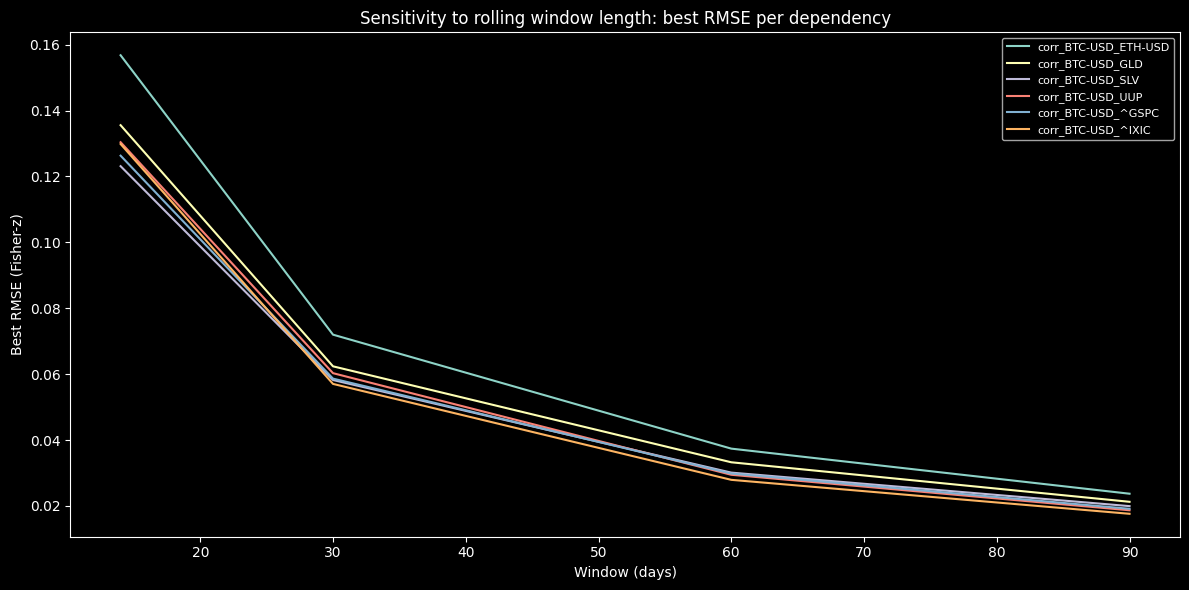

In [5]:
#график sensitivity RMSE vs window (по лучшей модели)
import matplotlib.pyplot as plt

# окна по порядку
order = sorted(best["window"].unique())
deps = best["dependency"].unique()

plt.figure(figsize=(12,6))
for dep in deps:
    tmp = best[best["dependency"]==dep].set_index("window").reindex(order)
    plt.plot(order, tmp["RMSE"].values, label=dep)

plt.xlabel("Window (days)")
plt.ylabel("Best RMSE (Fisher-z)")
plt.title("Sensitivity to rolling window length: best RMSE per dependency")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
#DM tests: фильтр “значимо” + топ улучшений
dm_path = RESULTS / "dm_tests.csv"
if dm_path.exists():
    dm = pd.read_csv(dm_path)
    display(dm.head())

    # ожидаемые колонки: dependency, window, model_a, model_b, dm_stat, p_value (если иначе — скажи, я подстрою)
    sig = dm[dm["p_value"] < 0.05].copy()
    print("Significant DM tests (p<0.05):", len(sig))
    display(sig.sort_values("p_value").head(30))
else:
    print("dm_tests.csv not found")

,dependency,window,space,model,benchmark,DM_stat,p_value,n
0,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,Naive_Last,-11.880939,0.000000e+00,1255.0
1,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,DCC_GARCH,16.354195,0.000000e+00,1255.0
2,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,Naive_Last,-9.833022,0.000000e+00,1239.0
3,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,DCC_GARCH,18.051013,0.000000e+00,1239.0
4,corr_BTC-USD_^GSPC,60,fisher_z,Ridge,Naive_Last,-8.205213,6.661338e-16,1209.0


Significant DM tests (p<0.05): 48


,dependency,window,space,model,benchmark,DM_stat,p_value,n
0,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,Naive_Last,-11.880939,0.0,1255.0
1,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,DCC_GARCH,16.354195,0.0,1255.0
2,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,Naive_Last,-9.833022,0.0,1239.0
3,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,DCC_GARCH,18.051013,0.0,1239.0
5,corr_BTC-USD_^GSPC,60,fisher_z,Ridge,DCC_GARCH,22.059640,0.0,1209.0
7,corr_BTC-USD_^GSPC,90,fisher_z,Ridge,DCC_GARCH,27.272930,0.0,1179.0
9,corr_BTC-USD_^IXIC,14,fisher_z,Ridge,DCC_GARCH,15.910565,0.0,1255.0
8,corr_BTC-USD_^IXIC,14,fisher_z,Ridge,Naive_Last,-11.722002,0.0,1255.0
12,corr_BTC-USD_^IXIC,60,fisher_z,Ridge,Naive_Last,-8.414652,0.0,1209.0
13,corr_BTC-USD_^IXIC,60,fisher_z,Ridge,DCC_GARCH,24.506827,0.0,1209.0


model
AR1           21
Naive_Last     3
Name: count, dtype: int64

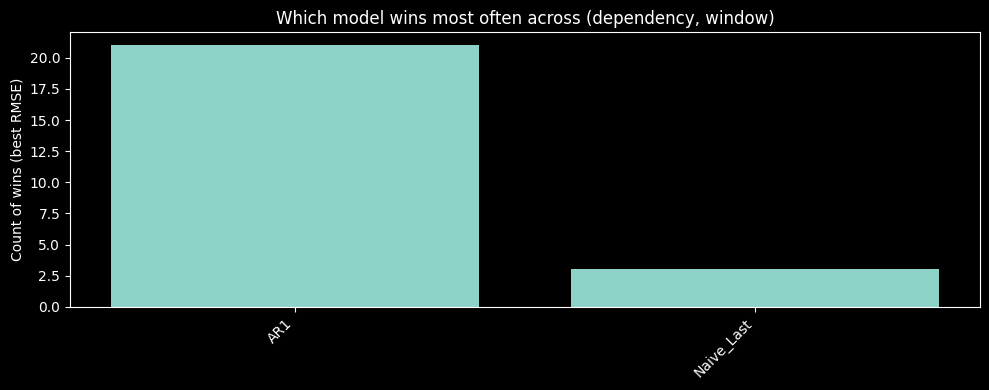

In [7]:
#“кто выигрывает чаще” (бар-чарт)
wins = best["model"].value_counts()
display(wins)

plt.figure(figsize=(10,4))
plt.bar(wins.index, wins.values)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Count of wins (best RMSE)")
plt.title("Which model wins most often across (dependency, window)")
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd
from pathlib import Path

ROOT = Path(".").resolve()
RESULTS = ROOT / "outputs" / "results"

dm = pd.read_csv(RESULTS / "dm_tests.csv")
print(dm.columns.tolist())
dm.head()

['dependency', 'window', 'space', 'model', 'benchmark', 'DM_stat', 'p_value', 'n']


,dependency,window,space,model,benchmark,DM_stat,p_value,n
0,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,Naive_Last,-11.880939,0.000000e+00,1255.0
1,corr_BTC-USD_^GSPC,14,fisher_z,Ridge,DCC_GARCH,16.354195,0.000000e+00,1255.0
2,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,Naive_Last,-9.833022,0.000000e+00,1239.0
3,corr_BTC-USD_^GSPC,30,fisher_z,Ridge,DCC_GARCH,18.051013,0.000000e+00,1239.0
4,corr_BTC-USD_^GSPC,60,fisher_z,Ridge,Naive_Last,-8.205213,6.661338e-16,1209.0


DM win matrix (counts where model beats benchmark):


benchmark,DCC_GARCH,Naive_Last
model,,
Ridge,0,24


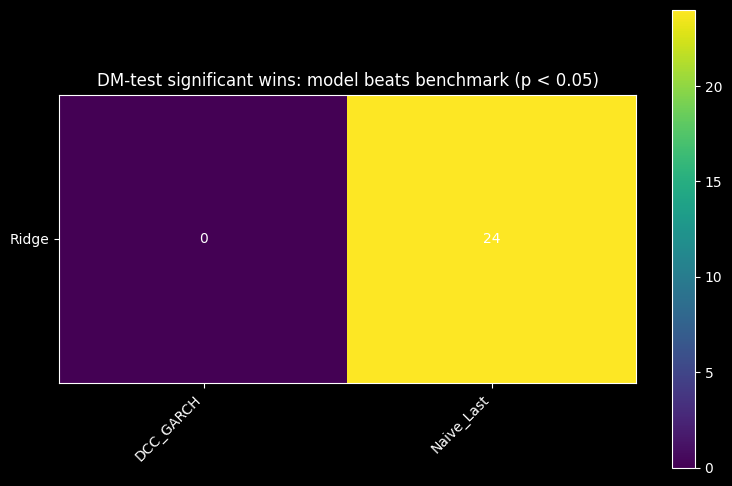

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

ROOT = Path(".").resolve()
RESULTS = ROOT / "outputs" / "results"

dm = pd.read_csv(RESULTS / "dm_tests.csv")

# только значимые
dm_sig = dm[dm["p_value"] < 0.05].copy()

# winner: если DM_stat < 0 => model лучше benchmark, иначе benchmark лучше model
dm_sig["winner"] = np.where(dm_sig["DM_stat"] < 0, dm_sig["model"], dm_sig["benchmark"])

# считаем "победы" по парам (model vs benchmark)
wins = (
    dm_sig
    .groupby(["model", "benchmark"])["winner"]
    .apply(lambda s: (s == s.name[0]).sum())  # сколько раз выиграл именно model
    .unstack(fill_value=0)
)

print("DM win matrix (counts where model beats benchmark):")
display(wins)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(wins.values)

ax.set_xticks(np.arange(len(wins.columns)))
ax.set_yticks(np.arange(len(wins.index)))
ax.set_xticklabels(wins.columns, rotation=45, ha="right")
ax.set_yticklabels(wins.index)

for i in range(wins.shape[0]):
    for j in range(wins.shape[1]):
        ax.text(j, i, int(wins.values[i, j]), ha="center", va="center")

ax.set_title("DM-test significant wins: model beats benchmark (p < 0.05)")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [13]:
summary = (
    dm_sig.assign(
        model_wins = (dm_sig["DM_stat"] < 0).astype(int),
        bench_wins = (dm_sig["DM_stat"] > 0).astype(int)
    )
    .groupby(["model","benchmark"], as_index=False)[["model_wins","bench_wins"]]
    .sum()
)

display(summary.sort_values(["model_wins","bench_wins"], ascending=False))

,model,benchmark,model_wins,bench_wins
1,Ridge,Naive_Last,24,0
0,Ridge,DCC_GARCH,0,24


In [14]:
#DM-test DCC vs XGBoost
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats

ROOT = Path(".").resolve()
PRED_DIR = ROOT / "outputs" / "predictions"

# выбрать любой файл (например w30 fisher_z)
file = next(PRED_DIR.glob("*w30*fisher_z*predictions.csv"))
print("Using:", file.name)

df = pd.read_csv(file)

required_cols = ["y_true", "DCC_GARCH", "XGB_GPU"]
for c in required_cols:
    if c not in df.columns:
        raise ValueError(f"Missing column: {c}")

# удаляем NaN
df = df.dropna(subset=required_cols).copy()

y = df["y_true"].values
dcc = df["DCC_GARCH"].values
xgb = df["XGB_GPU"].values

# квадратичные ошибки
e_dcc = (y - dcc)**2
e_xgb = (y - xgb)**2

# разница потерь
d = e_dcc - e_xgb

T = len(d)
mean_d = np.mean(d)
var_d = np.var(d, ddof=1)

DM_stat = mean_d / np.sqrt(var_d / T)

# двухсторонний тест
p_value = 2 * (1 - stats.norm.cdf(abs(DM_stat)))

print("Observations:", T)
print("DM_stat:", DM_stat)
print("p_value:", p_value)

if p_value < 0.05:
    if DM_stat < 0:
        print("→ DCC significantly better than XGBoost")
    else:
        print("→ XGBoost significantly better than DCC")
else:
    print("→ No significant difference")

Using: corr_BTC-USD_ETH-USD_w30_fisher_z_predictions.csv
Observations: 0
DM_stat: nan
p_value: nan
→ No significant difference


D:\progr\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
D:\progr\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
D:\progr\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:4232: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
D:\progr\.venv\Lib\site-packages\numpy\_core\_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
D:\progr\.venv\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [16]:
from pathlib import Path
import pandas as pd

ROOT = Path(".").resolve()
PRED_DIR = ROOT / "outputs" / "predictions"

print("Notebook ROOT:", ROOT)
print("Pred dir:", PRED_DIR)
print("Exists pred dir?", PRED_DIR.exists())

files = sorted(PRED_DIR.glob("*_predictions.csv"))
print("Found prediction files:", len(files))
for f in files[:20]:
    print(" -", f.name)

# посмотрим один файл (если есть)
if files:
    df0 = pd.read_csv(files[0], nrows=3)
    print("\nSample file columns:", df0.columns.tolist())

Notebook ROOT: D:\progr
Pred dir: D:\progr\outputs\predictions
Exists pred dir? True
Found prediction files: 30
 - corr_BTC-USD_^GSPC_predictions.csv
 - corr_BTC-USD_^GSPC_w14_fisher_z_predictions.csv
 - corr_BTC-USD_^GSPC_w30_fisher_z_predictions.csv
 - corr_BTC-USD_^GSPC_w60_fisher_z_predictions.csv
 - corr_BTC-USD_^GSPC_w90_fisher_z_predictions.csv
 - corr_BTC-USD_^IXIC_predictions.csv
 - corr_BTC-USD_^IXIC_w14_fisher_z_predictions.csv
 - corr_BTC-USD_^IXIC_w30_fisher_z_predictions.csv
 - corr_BTC-USD_^IXIC_w60_fisher_z_predictions.csv
 - corr_BTC-USD_^IXIC_w90_fisher_z_predictions.csv
 - corr_BTC-USD_ETH-USD_predictions.csv
 - corr_BTC-USD_ETH-USD_w14_fisher_z_predictions.csv
 - corr_BTC-USD_ETH-USD_w30_fisher_z_predictions.csv
 - corr_BTC-USD_ETH-USD_w60_fisher_z_predictions.csv
 - corr_BTC-USD_ETH-USD_w90_fisher_z_predictions.csv
 - corr_BTC-USD_GLD_predictions.csv
 - corr_BTC-USD_GLD_w14_fisher_z_predictions.csv
 - corr_BTC-USD_GLD_w30_fisher_z_predictions.csv
 - corr_BTC-USD_GL

Candidate files: 24
Processed rows: 24


,dependency,window,model,benchmark,DM_stat,p_value,n,RMSE_DCC,RMSE_XGB,file
0,corr_BTC-USD_ETH-USD,14,DCC_GARCH,XGB_GPU_retrained,11.987884,0.0,405,0.295663,0.149776,corr_BTC-USD_ETH-USD_w14_fisher_z_predictions.csv
1,corr_BTC-USD_ETH-USD,30,DCC_GARCH,XGB_GPU_retrained,13.778966,0.0,401,0.178993,0.074315,corr_BTC-USD_ETH-USD_w30_fisher_z_predictions.csv
2,corr_BTC-USD_ETH-USD,60,DCC_GARCH,XGB_GPU_retrained,14.684507,0.0,395,0.133608,0.039184,corr_BTC-USD_ETH-USD_w60_fisher_z_predictions.csv
3,corr_BTC-USD_ETH-USD,90,DCC_GARCH,XGB_GPU_retrained,13.583647,0.0,389,0.137265,0.024595,corr_BTC-USD_ETH-USD_w90_fisher_z_predictions.csv
4,corr_BTC-USD_GLD,14,DCC_GARCH,XGB_GPU_retrained,11.886258,0.0,405,0.314185,0.144574,corr_BTC-USD_GLD_w14_fisher_z_predictions.csv
5,corr_BTC-USD_GLD,30,DCC_GARCH,XGB_GPU_retrained,12.513652,0.0,401,0.180841,0.072059,corr_BTC-USD_GLD_w30_fisher_z_predictions.csv
6,corr_BTC-USD_GLD,60,DCC_GARCH,XGB_GPU_retrained,13.904126,0.0,395,0.106751,0.041557,corr_BTC-USD_GLD_w60_fisher_z_predictions.csv
7,corr_BTC-USD_GLD,90,DCC_GARCH,XGB_GPU_retrained,14.372766,0.0,389,0.078454,0.028085,corr_BTC-USD_GLD_w90_fisher_z_predictions.csv
8,corr_BTC-USD_SLV,14,DCC_GARCH,XGB_GPU_retrained,11.954526,0.0,405,0.315928,0.136660,corr_BTC-USD_SLV_w14_fisher_z_predictions.csv
9,corr_BTC-USD_SLV,30,DCC_GARCH,XGB_GPU_retrained,15.615501,0.0,401,0.214102,0.067123,corr_BTC-USD_SLV_w30_fisher_z_predictions.csv


✅ Saved: D:\progr\outputs\results\dm_xgb_vs_dcc.csv

Significant comparisons: 24 out of 24
DCC wins: 0 | XGB wins: 24


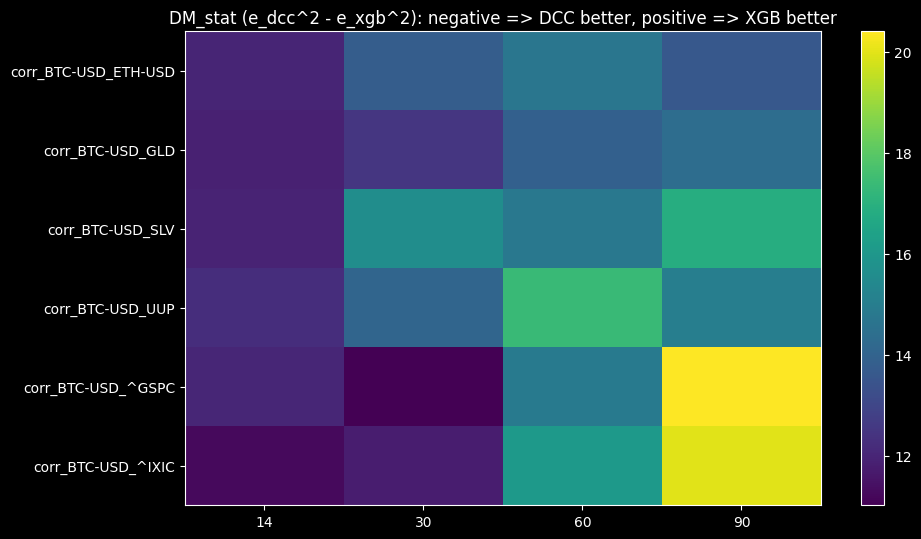

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import xgboost as xgb

ROOT = Path(r"D:\progr")
PRED_DIR = ROOT / "outputs" / "predictions"
RESULTS_DIR = ROOT / "outputs" / "results"
TABLES_DIR = ROOT / "outputs" / "tables"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def dm_test_sqerr(y, a_pred, b_pred):
    y = np.asarray(y, dtype=float)
    a_pred = np.asarray(a_pred, dtype=float)
    b_pred = np.asarray(b_pred, dtype=float)

    m = (~np.isnan(y)) & (~np.isnan(a_pred)) & (~np.isnan(b_pred))
    y, a_pred, b_pred = y[m], a_pred[m], b_pred[m]

    T = len(y)
    if T < 50:
        return np.nan, np.nan, T

    d = (y - a_pred) ** 2 - (y - b_pred) ** 2  # DCC - XGB
    md = float(np.mean(d))
    vd = float(np.var(d, ddof=1))
    if vd <= 0 or not np.isfinite(vd):
        return np.nan, np.nan, T

    DM = md / math.sqrt(vd / T)
    p = 2.0 * (1.0 - norm_cdf(abs(DM)))
    return float(DM), float(p), T

def build_lags(s: pd.Series, n_lags: int):
    return pd.concat([s.shift(k).rename(f"lag_{k}") for k in range(1, n_lags+1)], axis=1)

def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    m = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    if m.sum() == 0:
        return float("nan")
    return float(np.sqrt(np.mean((y_true[m] - y_pred[m])**2)))

# settings
N_LAGS = 30
TEST_FRAC = 0.20
MIN_TEST = 200

XGB_PARAMS = dict(
    n_estimators=1500,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    device="cuda",
    random_state=42,
)

# IMPORTANT: only files with window + fisher_z
files = sorted(PRED_DIR.glob("*_w*_fisher_z_predictions.csv"))
print("Candidate files:", len(files))
assert len(files) > 0, "No *_w*_fisher_z_predictions.csv found."

rows = []
skipped = []

for f in files:
    name = f.stem
    dep = name.split("_w")[0]
    rest = name.split("_w")[1]  # "30_fisher_z_predictions"
    window = int(rest.split("_")[0])

    df = pd.read_csv(f)

    if "DCC_GARCH" not in df.columns:
        skipped.append((f.name, "no DCC_GARCH column"))
        continue
    if "y_true" not in df.columns:
        skipped.append((f.name, "no y_true column"))
        continue

    y = pd.to_numeric(df["y_true"], errors="coerce")
    dcc = pd.to_numeric(df["DCC_GARCH"], errors="coerce")

    aligned = pd.concat([y.rename("y_true"), dcc.rename("dcc"), build_lags(y, N_LAGS)], axis=1).dropna().reset_index(drop=True)

    if len(aligned) < (MIN_TEST + 100):
        skipped.append((f.name, f"too few rows after lags/dropna: {len(aligned)}"))
        continue

    test_size = max(MIN_TEST, int(len(aligned) * TEST_FRAC))
    split = len(aligned) - test_size

    X_train = aligned.drop(columns=["y_true","dcc"]).iloc[:split]
    y_train = aligned["y_true"].iloc[:split]
    X_test  = aligned.drop(columns=["y_true","dcc"]).iloc[split:]
    y_test  = aligned["y_true"].iloc[split:].values
    dcc_test = aligned["dcc"].iloc[split:].values

    # Train XGB GPU (retrained) on same target
    model = xgb.XGBRegressor(**XGB_PARAMS)
    model.fit(X_train, y_train)
    xgb_pred = model.predict(X_test)

    DM, p, n = dm_test_sqerr(y_test, dcc_test, xgb_pred)

    rows.append({
        "dependency": dep,
        "window": window,
        "model": "DCC_GARCH",
        "benchmark": "XGB_GPU_retrained",
        "DM_stat": DM,
        "p_value": p,
        "n": n,
        "RMSE_DCC": rmse(y_test, dcc_test),
        "RMSE_XGB": rmse(y_test, xgb_pred),
        "file": f.name
    })

dm_xgb_vs_dcc = pd.DataFrame(rows).sort_values(["dependency","window"]).reset_index(drop=True)
print("Processed rows:", len(dm_xgb_vs_dcc))
display(dm_xgb_vs_dcc.head(20))

out_csv = RESULTS_DIR / "dm_xgb_vs_dcc.csv"
dm_xgb_vs_dcc.to_csv(out_csv, index=False)
print("✅ Saved:", out_csv)

if skipped:
    print("\nSkipped (first 10):")
    for a,b in skipped[:10]:
        print(" -", a, "=>", b)

# summary: negative DM => DCC better; positive => XGB better
sig = dm_xgb_vs_dcc[dm_xgb_vs_dcc["p_value"] < 0.05].copy()
print("\nSignificant comparisons:", len(sig), "out of", len(dm_xgb_vs_dcc))
print("DCC wins:", int((sig["DM_stat"] < 0).sum()), "| XGB wins:", int((sig["DM_stat"] > 0).sum()))

# heatmap DM_stat
pivot = dm_xgb_vs_dcc.pivot_table(index="dependency", columns="window", values="DM_stat", aggfunc="mean")
plt.figure(figsize=(10, 4 + 0.25*len(pivot.index)))
im = plt.imshow(pivot.values, aspect="auto")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.title("DM_stat (e_dcc^2 - e_xgb^2): negative => DCC better, positive => XGB better")
plt.colorbar(im)
plt.tight_layout()
plt.show()